# K-Medoids

K-Means (`27_kmeans`) with one change: a cluster is represented by a **medoid** — an actual data point, the member with the smallest total distance to all the others — instead of a mean.

| | K-Means | K-Medoids |
|---|---|---|
| Centre | mean (may not be a real sample) | medoid (always a real sample) |
| Outliers | drag the mean | barely move the medoid |
| Distance | squared Euclidean | any metric (Euclidean, Manhattan, ...) |
| Cost | cheap | `O(n²)` — needs the pairwise distance matrix |

The algorithm alternates two steps until nothing changes: assign every point to its nearest medoid; then in each cluster, pick the member minimizing the summed distance to its cluster-mates as the new medoid. It is restarted from several k-means++-style seeds and the lowest-cost result is kept.

This is the Voronoi-iteration variant, which is simpler and faster than the classic PAM swap search but can land in a slightly worse optimum.

## Usage

```python
# (the class is defined in the Implementation section below)

model = KMedoids(n_clusters=3, metric="manhattan").fit(X)
model.labels_            # cluster of each training point
model.cluster_centers_   # the medoids (rows of X)
model.predict(X_new)
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


def _pairwise(A, B, metric):
    diff = A[:, None, :] - B[None, :, :]
    if metric == "euclidean":
        return np.sqrt((diff**2).sum(axis=2))
    if metric == "manhattan":
        return np.abs(diff).sum(axis=2)
    raise ValueError(f"unknown metric: {metric}")


class KMedoids:
    """Like K-Means, but each cluster is represented by a MEDOID: an actual data point, the
    member with the smallest total distance to the rest of its cluster. Consequences:

    - robust to outliers (a median-like centre, not a mean that gets dragged),
    - works with any distance metric (the algorithm only reads a distance matrix),
    - cluster centres are always real, interpretable samples.

    Alternates assign -> re-pick each medoid (Voronoi iteration) until nothing changes, restarted
    n_init times from different seeds; the lowest-cost run wins.

    ponytail: Voronoi iteration, not the full PAM swap search; it can settle in a slightly worse
    local optimum. O(n^2) memory for the distance matrix."""

    def __init__(self, n_clusters=3, metric="euclidean", max_iter=100, n_init=5, random_state=0):
        self.n_clusters = n_clusters
        self.metric = metric
        self.max_iter = max_iter
        self.n_init = n_init
        self.random_state = random_state

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        n, k = len(X), self.n_clusters
        D = _pairwise(X, X, self.metric)
        rng = np.random.default_rng(self.random_state)

        best_cost = np.inf
        for _ in range(self.n_init):
            medoids = self._init(D, rng)
            for _ in range(self.max_iter):
                labels = D[:, medoids].argmin(axis=1)
                new = medoids.copy()
                for c in range(k):
                    members = np.flatnonzero(labels == c)
                    if len(members):  # the member closest to all the others becomes the medoid
                        new[c] = members[D[np.ix_(members, members)].sum(axis=1).argmin()]
                if np.array_equal(new, medoids):
                    break
                medoids = new
            labels = D[:, medoids].argmin(axis=1)
            cost = D[np.arange(n), medoids[labels]].sum()
            if cost < best_cost:
                best_cost, best_medoids, best_labels = cost, medoids, labels

        self.medoid_indices_ = best_medoids
        self.cluster_centers_ = X[best_medoids]
        self.labels_ = best_labels
        self.inertia_ = best_cost  # total distance from every point to its medoid
        return self

    def _init(self, D, rng):
        # k-means++ style: spread the starting medoids out, far points more likely
        medoids = [rng.integers(len(D))]
        for _ in range(1, self.n_clusters):
            nearest = D[:, medoids].min(axis=1) ** 2
            medoids.append(rng.choice(len(D), p=nearest / nearest.sum()))
        return np.array(medoids)

    def predict(self, X):
        return _pairwise(np.asarray(X, dtype=float), self.cluster_centers_, self.metric).argmin(axis=1)

## See it work

### 1. Medoids are real data points, and ignore outliers

K-Means puts each centre at the **mean** of its cluster, so a few extreme points drag it away. K-Medoids restricts each centre to an **actual data point** (the one with the smallest total distance to its cluster), which barely moves when outliers appear. Same data, 15 far-away outliers added:

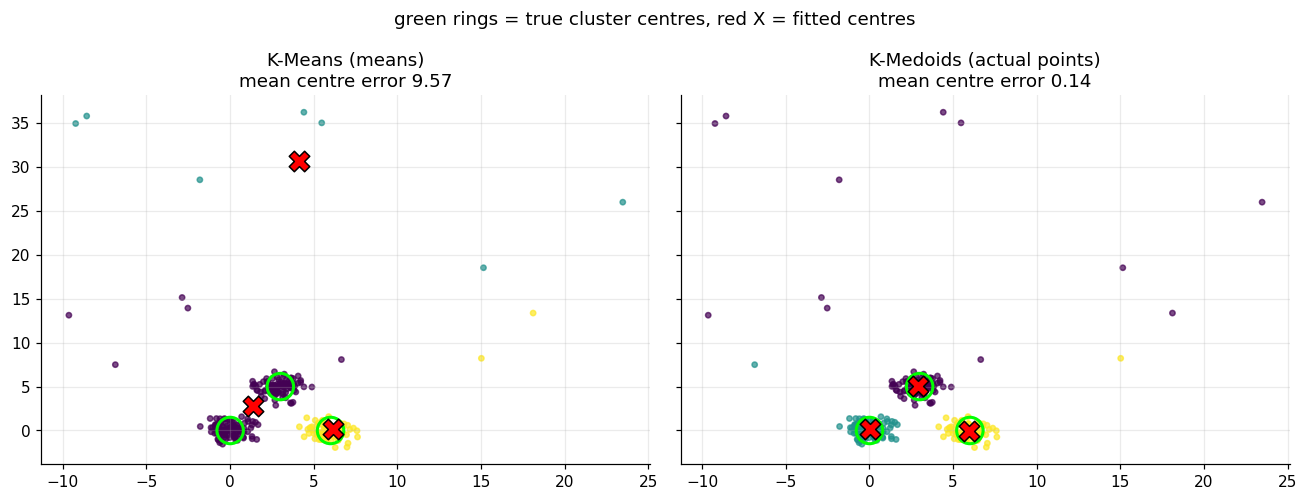

In [3]:
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans as SkKMeans

X, _ = make_blobs(n_samples=300, centers=[[0, 0], [6, 0], [3, 5]], cluster_std=0.7, random_state=0)
rng = np.random.default_rng(1)
Xo = np.vstack([X, rng.uniform(-15, 25, size=(15, 2)) * [1, 1] + [0, 12]])      # outliers high above the data

km = SkKMeans(3, n_init=10, random_state=0).fit(Xo)
med = KMedoids(n_clusters=3).fit(Xo)
true_centres = np.array([[0, 0], [6, 0], [3, 5]])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True, sharey=True)
for ax, name, centres, labels in [(axes[0], "K-Means (means)", km.cluster_centers_, km.labels_), (axes[1], "K-Medoids (actual points)", med.cluster_centers_, med.labels_)]:
    ax.scatter(*Xo.T, c=labels, cmap="viridis", s=12, alpha=0.7); ax.scatter(*centres.T, c="red", marker="X", s=180, edgecolor="k", zorder=3)
    ax.scatter(*true_centres.T, c="none", edgecolors="lime", marker="o", s=300, linewidths=2, zorder=2)
    ax.set_title(f"{name}\nmean centre error {np.mean(np.min(np.linalg.norm(centres[:, None] - true_centres[None], axis=2), axis=1)):.2f}")
plt.suptitle("green rings = true cluster centres, red X = fitted centres"); plt.tight_layout(); plt.show()

### 2. The centres are members of the dataset

`medoid_indices_` are row numbers in `X`. That makes the cluster centres directly interpretable (you can show the actual example), and lets K-Medoids use **any distance** (here Manhattan), because it only ever needs pairwise distances, never an average.

In [4]:
for metric in ("euclidean", "manhattan"):
    m = KMedoids(n_clusters=3, metric=metric).fit(X)
    print(f"{metric:10s} medoid rows: {m.medoid_indices_}   total within-cluster distance: {m.inertia_:.1f}")
    assert np.allclose(m.cluster_centers_, X[m.medoid_indices_])

euclidean  medoid rows: [ 83 197 160]   total within-cluster distance: 263.2
manhattan  medoid rows: [197  83 160]   total within-cluster distance: 335.2


## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [5]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import adjusted_rand_score

# clean data: K-Medoids and K-Means should find the same clusters
X, _ = make_blobs(n_samples=300, centers=3, cluster_std=0.8, random_state=42)
medoids = KMedoids(n_clusters=3).fit(X)
means = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X)
ari = adjusted_rand_score(medoids.labels_, means.labels_)
print("clean blobs: agreement with K-Means (ARI) = %.4f" % ari)
assert ari > 0.95

# two blobs centred at (0,0) and (20,0), plus 3 extreme outliers far to the left of the first
rng = np.random.default_rng(0)
X = np.vstack([
    rng.normal([0, 0], 0.5, (60, 2)),
    rng.normal([20, 0], 0.5, (60, 2)),
    [[-30.0, 0.0], [-31.0, 1.0], [-29.0, -1.0]],
])
medoids = KMedoids(n_clusters=2).fit(X)
means = KMeans(n_clusters=2, n_init=10, random_state=0).fit(X)

def error_at_first_blob(centers):  # distance from the true centre (0, 0) to the nearest found centre
    return np.linalg.norm(centers - np.array([0.0, 0.0]), axis=1).min()

e_medoid = error_at_first_blob(medoids.cluster_centers_)
e_mean = error_at_first_blob(means.cluster_centers_)
print("with outliers, centre of the first blob is off by: medoid=%.2f  kmeans=%.2f" % (e_medoid, e_mean))
assert e_medoid < e_mean

clean blobs: agreement with K-Means (ARI) = 1.0000
with outliers, centre of the first blob is off by: medoid=0.11  kmeans=1.43


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [6]:
import numpy as np


def _two_blobs_with_outliers():
    rng = np.random.default_rng(0)
    blob0 = rng.normal([0, 0], 0.5, (60, 2))
    blob1 = rng.normal([20, 0], 0.5, (60, 2))
    outliers = np.array([[-30.0, 0.0], [-31.0, 1.0], [-29.0, -1.0]])  # far to the left of blob0
    return np.vstack([blob0, blob1, outliers])


def test_medoids_are_actual_data_points():
    X = _two_blobs_with_outliers()
    model = KMedoids(n_clusters=2).fit(X)
    for center in model.cluster_centers_:
        assert (X == center).all(axis=1).any()
    assert np.array_equal(model.cluster_centers_, X[model.medoid_indices_])


def test_outliers_drag_the_mean_but_not_the_medoid():
    X = _two_blobs_with_outliers()
    model = KMedoids(n_clusters=2).fit(X)
    c = model.cluster_centers_[np.argmin(np.abs(model.cluster_centers_[:, 0]))]  # blob0's centre
    members = X[model.labels_ == model.predict(c[None])[0]]
    assert len(members) == 63                      # blob0 plus the 3 outliers
    assert abs(c[0]) < 1.0                          # the medoid stays inside blob0
    assert abs(members.mean(axis=0)[0]) > 1.0       # a K-Means style centroid would be dragged left


def test_manhattan_metric_and_predict():
    rng = np.random.default_rng(1)
    X = np.vstack([rng.normal(-5, 0.5, (40, 2)), rng.normal(5, 0.5, (40, 2))])
    model = KMedoids(n_clusters=2, metric="manhattan").fit(X)
    assert len(set(model.labels_[:40])) == 1 and len(set(model.labels_[40:])) == 1
    assert model.labels_[0] != model.labels_[-1]
    assert model.predict(np.array([[-5.0, -5.0], [5.0, 5.0]])).tolist() == [model.labels_[0], model.labels_[-1]]

In [7]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_medoids_are_actual_data_points
PASS test_outliers_drag_the_mean_but_not_the_medoid
PASS test_manhattan_metric_and_predict

all 3 tests passed


## Takeaways

- **Use it** when the data has outliers, when you want interpretable prototypes (real examples as cluster centres), or when you only have a distance matrix (strings, graphs, mixed data) rather than coordinates you can average.
- **Algorithm (alternate / "Voronoi iteration"):** assign each point to the nearest medoid; for each cluster pick the member with minimal total distance to the others; repeat, with several random restarts (`n_init`).
- **Cost:** `O(k·(n/k)²)` per iteration from the pairwise distances; heavier than K-Means.
- **Interview line:** *"K-Medoids = K-Means with centres constrained to data points, minimising total distance instead of squared distance: robust to outliers and works with arbitrary dissimilarities."*